# Hospital 30-day readmission - training notebook
Runs the same code as `python -m src.train`. Set `RETRAIN=True` to retrain here (~2 min); otherwise it reads saved artifacts.

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config as C
RETRAIN = False
if RETRAIN:
    from src.train import run; run()
art = C.artifact_dir()
m = json.load(open(art/'metrics.json'))

## 1. Data after cleaning (GST fixed, diagnosis mapped, history features, 45-day censoring)

In [2]:
df = pd.read_csv(C.data_dir()/'modeling_table.csv', parse_dates=['admission_date'])
print(df.shape, 'prevalence', round(df[C.TARGET].mean(), 3))
df.head()

(84516, 26) prevalence 0.13


,admission_id,patient_id,admission_date,age,chronic_conditions,los_days,prior_adm_180d,prior_adm_30d,opd_visits_90d,n_lab_tests,...,billing_total,discharge_dow,admission_month,hospital_id,sex,insurance,admission_type,discharge_disposition,diagnosis_group,readmitted_30d
0,13925,25266,2023-01-01,81,1,2.0,0,0,0,2.0,...,23244.71,1.0,1,PUN-HINJEWADI,M,Private,Referral,Home,other,0
1,64423,32888,2023-01-01,46,1,3.0,0,0,0,2.0,...,29840.54,2.0,1,PUN-KOTHRUD,F,Self-pay,Elective,Home,diabetes,0
2,52494,36796,2023-01-01,52,2,4.0,0,0,0,3.0,...,44816.01,3.0,1,PUN-KOTHRUD,M,Corporate,Referral,Home,pneumonia,0
3,21330,39609,2023-01-01,41,1,6.0,0,0,0,1.0,...,84219.07,5.0,1,PUN-WAKAD,F,Private,Elective,Home,surgical,0
4,27477,29798,2023-01-01,39,1,2.0,0,0,0,3.0,...,29405.49,1.0,1,PUN-KOTHRUD,M,Government scheme,Emergency,Home with follow-up,kidney_disease,0


In [3]:
df.isna().mean().round(3)[lambda s: s > 0]

los_days         0.060
hba1c            0.702
creatinine       0.700
hemoglobin       0.702
sodium           0.698
wbc              0.702
discharge_dow    0.060
dtype: float64

## 2. Time-based split
Train < validation < test by admission date (no shuffling).

In [4]:
print(m['n_rows'], m['time_ranges'])

{'train': 59161, 'valid': 12677, 'test': 12678} {'train_end': '2024-04-24', 'valid_end': '2024-08-05', 'test_end': '2024-11-16'}


## 3. Four models + dummy (validation)

In [5]:
pd.read_csv(art/'model_comparison.csv').round(4)

,model,valid_roc_auc,valid_pr_auc,valid_brier
0,dummy_prior,0.5000,0.1374,0.1187
1,logistic_regression,0.7994,0.4564,0.1829
2,random_forest,0.7953,0.4476,0.1521
3,xgboost,0.8036,0.4815,0.1772
4,lightgbm,0.8024,0.4760,0.1772


## 4. Tuned model, test metrics and success criteria

In [6]:
print('best model:', m['best_model']); print('best params:', m['best_params'])
print('test:', {k: round(v, 3) for k, v in m['test'].items()})
print('rule baseline PR-AUC:', round(m['baseline_rule_test']['pr_auc'], 3), '| untuned LR PR-AUC:', round(m['baseline_logistic_test']['pr_auc'], 3))
print('improvement vs baseline: %.0f%% (met=%s)' % (m['improvement_over_baseline']*100, m['success_improvement_met']))
print('latency incl. SHAP: %.0f ms (met=%s)' % (m['inference_latency_ms_with_shap'], m['success_latency_met']))

best model: xgboost
best params: {'colsample_bytree': 0.5998368910791798, 'learning_rate': 0.06535283531563524, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 406, 'reg_lambda': 3.676275522134634, 'subsample': 0.7801997007878172}
test: {'roc_auc': 0.802, 'pr_auc': 0.462, 'brier': 0.188, 'threshold': 0.51, 'tp': 1293, 'fp': 2958, 'fn': 477, 'tn': 7950, 'recall': 0.731, 'precision': 0.304, 'flag_rate': 0.335, 'total_cost_inr': 61660500.0}
rule baseline PR-AUC: 0.191 | untuned LR PR-AUC: 0.443
improvement vs baseline: 141% (met=True)
latency incl. SHAP: 18 ms (met=True)


## 5. Cost-based threshold
FN = INR 40,000, FP = INR 1,500, TP = INR 29,500 (follow-up + the 70% it fails to prevent), TN = 0.

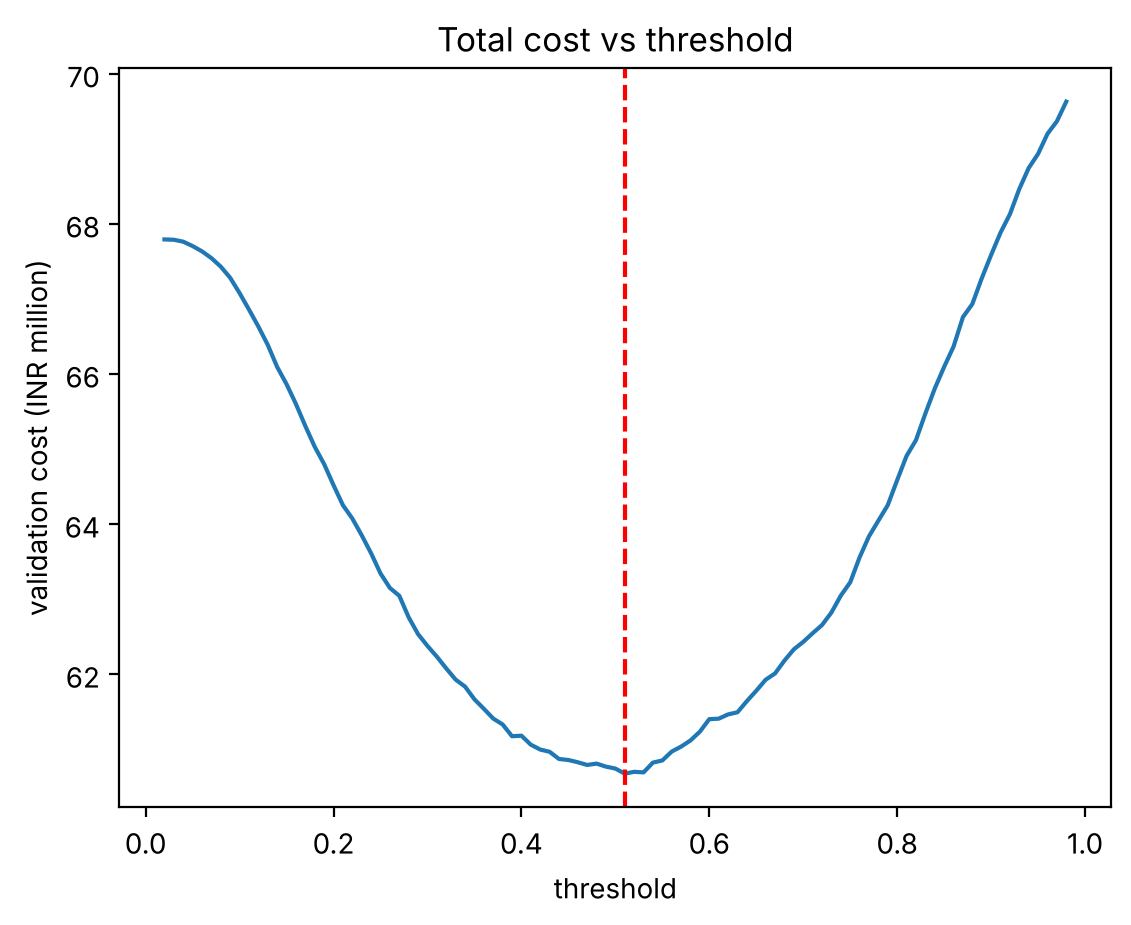

{'cost_at_chosen_threshold': 61660500.0, 'cost_threshold_0.5': 61681500.0, 'cost_flag_nobody': 70800000.0, 'cost_flag_everybody': 68577000.0, 'saving_vs_flag_nobody_inr': 9139500.0, 'saving_per_1000_patients_inr': 720894.4628490298}


In [7]:
c = pd.read_csv(art/'threshold_curve.csv')
plt.plot(c.threshold, c.total_cost_inr/1e6); plt.axvline(m['test']['threshold'], ls='--', c='r')
plt.xlabel('threshold'); plt.ylabel('validation cost (INR million)'); plt.title('Total cost vs threshold'); plt.show()
print(m['business'])

## 6. SHAP - global explanation

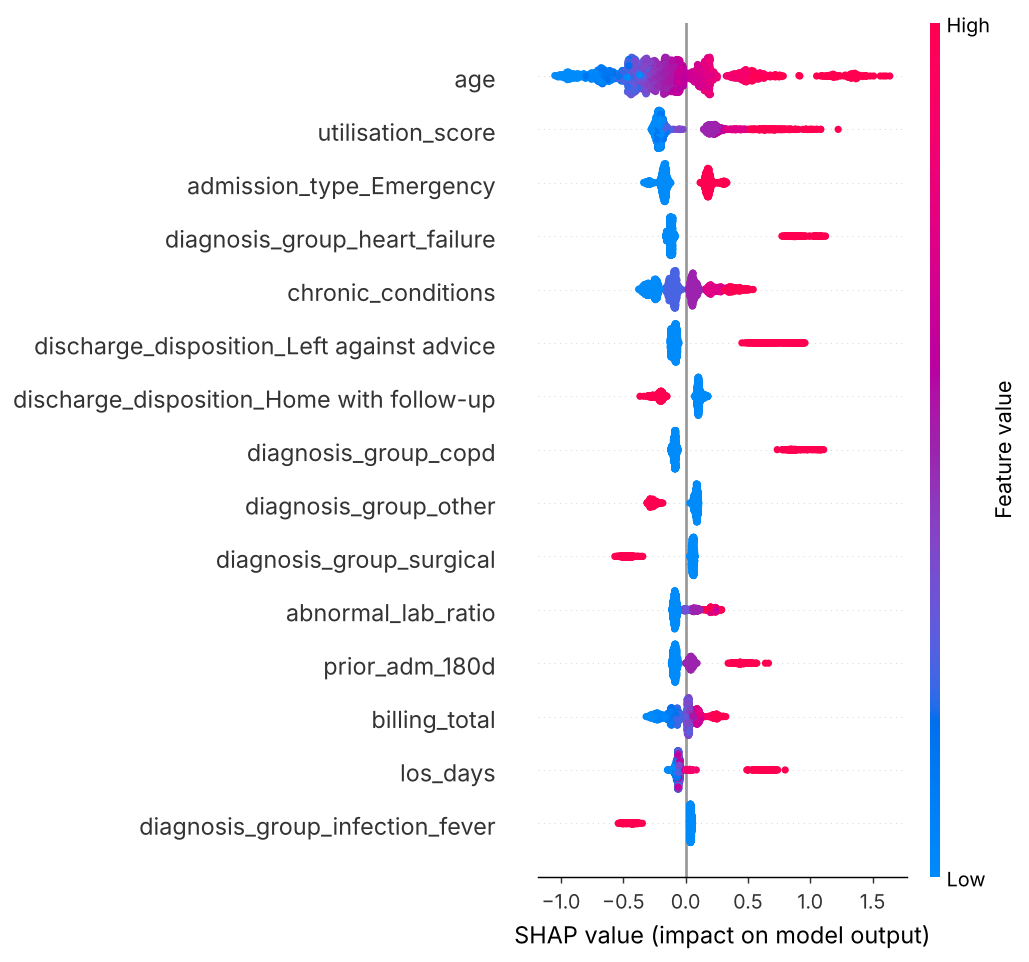

,feature,mean_abs_shap
0,age,0.373408
1,utilisation_score,0.255809
2,admission_type_Emergency,0.184256
3,diagnosis_group_heart_failure,0.180320
4,chronic_conditions,0.179889
5,discharge_disposition_Left against advice,0.146327
6,discharge_disposition_Home with follow-up,0.144728
7,diagnosis_group_copd,0.135149
8,diagnosis_group_other,0.131916
9,diagnosis_group_surgical,0.114688


In [8]:
display(Image(filename=str(art/'shap_summary.png')))
pd.read_csv(art/'shap_importance.csv').head(10)